# CSET485 — AI and Society | Assignment 1
## COMPAS Recidivism Risk Score Dataset

**Random seed:** `72`  
**Split:** 70% training / 30% testing  
**Important:** Run all cells from top to bottom. The notebook computes the numbers used in the report; do not invent or manually replace results. Review the outputs and edit the generated narrative in your own words before submission.

Dataset specified by the assignment: [ProPublica COMPAS two-year scores CSV](https://github.com/propublica/compas-analysis/raw/master/compas-scores-two-years.csv).

This is an educational audit, not a validated criminal-justice decision system. The target `is_recid` and the supplied `decile_score` are distinct measures; neither should be interpreted as ground truth about a person's future.

## 1. Setup and reproducibility

In [1]:
# If needed, uncomment in a notebook environment:
# %pip install pandas numpy scikit-learn statsmodels matplotlib seaborn requests

import warnings, json, math, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, roc_auc_score, classification_report)
from IPython.display import display

SEED = 72
DATA_URL = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
try:
    raw = pd.read_csv(DATA_URL)
except Exception as e:
    raise RuntimeError(
        "Could not download the CSV. Download compas-scores-two-years.csv from the "
        "ProPublica repository and place it next to this notebook, then replace "
        "pd.read_csv(DATA_URL) with pd.read_csv('compas-scores-two-years.csv')."
    ) from e

print("Raw shape:", raw.shape)
display(raw.head())

Raw shape: (7214, 53)


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,...,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


## 2. Preprocessing and documented decisions
We retain records with valid `is_recid` values (0/1), and exclude direct identifiers, post-outcome fields, and variables that would leak future information. The main features are age, sex, race, charge degree, juvenile counts, and prior count. Missing numeric values are median-imputed; missing categorical values use the most frequent category; categorical values are one-hot encoded; numeric values are standardized. Scaling is fit on training data only. Outliers are inspected but not automatically removed, because extreme criminal-history counts may be meaningful and deleting them could distort subgroup results.

In [2]:
required = ["decile_score", "is_recid", "age", "sex", "race", "c_charge_degree",
            "juv_fel_count", "juv_misd_count", "juv_other_count", "priors_count"]
missing_cols = [c for c in required if c not in raw.columns]
if missing_cols:
    raise ValueError(f"Required columns missing from downloaded dataset: {missing_cols}")

df = raw.copy()
# Target must be binary for the assignment's logistic model.
df = df[df["is_recid"].isin([0, 1])].copy()
# Drop rows missing either required target; do not impute outcomes.
df = df.dropna(subset=["decile_score", "is_recid"]).copy()

numeric_features = ["age", "juv_fel_count", "juv_misd_count", "juv_other_count", "priors_count"]
categorical_features = ["sex", "race", "c_charge_degree"]
features = numeric_features + categorical_features

# Report missingness and outlier audit before imputation.
missing_report = df[features + ["decile_score", "is_recid"]].isna().sum().sort_values(ascending=False)
print("Missing values before imputation:")
display(missing_report.to_frame("missing_count"))

outlier_rows = []
for c in numeric_features:
    q1, q3 = df[c].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    outlier_rows.append({"feature": c, "IQR_lower": lo, "IQR_upper": hi,
                         "outside_IQR_fences": int(((df[c] < lo) | (df[c] > hi)).sum())})
outlier_report = pd.DataFrame(outlier_rows)
print("IQR outlier audit (reported, not deleted):")
display(outlier_report)

X = df[features].copy()
y_linear = df["decile_score"].astype(float)
y_logistic = df["is_recid"].astype(int)

X_train, X_test, ylin_train, ylin_test, ylog_train, ylog_test = train_test_split(
    X, y_linear, y_logistic, test_size=0.30, random_state=SEED, stratify=y_logistic
)
numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])
print("Filtered rows:", len(df), "| train:", len(X_train), "| test:", len(X_test))
print("Random seed:", SEED)

Missing values before imputation:


,missing_count
age,0
juv_fel_count,0
juv_misd_count,0
juv_other_count,0
priors_count,0
sex,0
race,0
c_charge_degree,0
decile_score,0
is_recid,0


IQR outlier audit (reported, not deleted):


,feature,IQR_lower,IQR_upper,outside_IQR_fences
0,age,-0.5,67.5,61
1,juv_fel_count,0.0,0.0,282
2,juv_misd_count,0.0,0.0,415
3,juv_other_count,0.0,0.0,523
4,priors_count,-7.5,12.5,455


Filtered rows: 7214 | train: 5049 | test: 2165
Random seed: 72


## 3. Part 1 — Build and compare models
Model A is Linear Regression predicting `decile_score`. Per the assignment, its test predictions are thresholded at their test-set median. Model B is Logistic Regression predicting `is_recid`, thresholded at probability 0.5. The confusion matrix below compares the two model-derived flags—not predictions against the true outcome.

In [3]:
linear_model = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
logistic_model = Pipeline([("prep", preprocessor),
                           ("model", LogisticRegression(max_iter=3000, class_weight=None))])
linear_model.fit(X_train, ylin_train)
logistic_model.fit(X_train, ylog_train)

lin_pred = linear_model.predict(X_test)
lin_median = float(np.median(lin_pred))
flag_linear = (lin_pred >= lin_median).astype(int)
prob_log = logistic_model.predict_proba(X_test)[:, 1]
flag_log = (prob_log >= 0.5).astype(int)

cm_models = confusion_matrix(flag_linear, flag_log, labels=[0,1])
mismatch = int((flag_linear != flag_log).sum())
mismatch_pct = 100*mismatch/len(X_test)
print(f"Median linear prediction: {lin_median:.4f}")
print(f"Logistic probability threshold: 0.5000")
print("Rows = Linear Regression flag; columns = Logistic Regression flag")
display(pd.DataFrame(cm_models, index=["Linear low","Linear high"],
                     columns=["Logistic low","Logistic high"]))
print(f"Mismatched cases: {mismatch}/{len(X_test)} ({mismatch_pct:.2f}%)")
print("Linear target R²:", round(linear_model.score(X_test, ylin_test), 4))
print("Logistic accuracy vs is_recid:", round(accuracy_score(ylog_test, flag_log), 4))
print("Logistic ROC-AUC:", round(roc_auc_score(ylog_test, prob_log), 4))

Median linear prediction: 4.5154
Logistic probability threshold: 0.5000
Rows = Linear Regression flag; columns = Logistic Regression flag


,Logistic low,Logistic high
Linear low,1030,50
Linear high,187,898


Mismatched cases: 237/2165 (10.95%)
Linear target R²: 0.447
Logistic accuracy vs is_recid: 0.673
Logistic ROC-AUC: 0.7321


## 4. Part 2.1 — Simpson's paradox / subgroup effect audit
We fit logistic regression models with the same core predictors on the full test-independent dataset and within race groups. Coefficients are on the log-odds scale. A sign reversal is evidence consistent with a reversal in conditional association, but it does not by itself establish causality. If no sign reversal is found, compare confidence intervals and report a meaningful strength difference instead.

In [4]:
# statsmodels formula models provide coefficient confidence intervals and p-values.
# Use a compact interpretable specification and complete-case rows for this analysis.
import statsmodels.formula.api as smf
sim_df = df[["is_recid","priors_count","age","sex","race","c_charge_degree"]].dropna().copy()
sim_df["is_recid"] = sim_df["is_recid"].astype(int)
formula = 'is_recid ~ priors_count + age + C(sex) + C(c_charge_degree)'
race_counts = sim_df["race"].value_counts()
eligible_races = race_counts[race_counts >= 100].index.tolist()
if len(eligible_races) < 2:
    raise ValueError("Not enough race groups with at least 100 rows for subgroup analysis.")
# Choose two largest race groups to ensure usable estimates.
groups = race_counts.loc[eligible_races].sort_values(ascending=False).index[:2].tolist()
sim_models = {"Full dataset": smf.logit(formula, data=sim_df).fit(disp=False, maxiter=300)}
for g in groups:
    sub = sim_df[sim_df["race"] == g]
    try:
        sim_models[f"Race: {g}"] = smf.logit(formula, data=sub).fit(disp=False, maxiter=300)
    except Exception as e:
        print("Subgroup model failed for", g, ":", e)

coef_rows = []
for name, res in sim_models.items():
    ci = res.conf_int()
    for term in ["priors_count", "age"]:
        if term in res.params.index:
            coef_rows.append({"model": name, "predictor": term,
                              "coef_log_odds": res.params[term],
                              "CI_low": ci.loc[term,0], "CI_high": ci.loc[term,1],
                              "p_value": res.pvalues[term]})
simpson_table = pd.DataFrame(coef_rows)
display(simpson_table.round(4))
print("Selected subgroup race groups:", groups)

,model,predictor,coef_log_odds,CI_low,CI_high,p_value
0,Full dataset,priors_count,0.1625,0.1486,0.1764,0.0
1,Full dataset,age,-0.0478,-0.0525,-0.0431,0.0
2,Race: African-American,priors_count,0.1491,0.1316,0.1667,0.0
3,Race: African-American,age,-0.0553,-0.0626,-0.0479,0.0
4,Race: Caucasian,priors_count,0.1823,0.1535,0.2111,0.0
5,Race: Caucasian,age,-0.0373,-0.0445,-0.0301,0.0


Selected subgroup race groups: ['African-American', 'Caucasian']


## 5. Part 2.2 — Omitted-variable bias
We omit `priors_count`, a plausible confounder because prior history can be associated with both age/demographic composition and recidivism. Compare coefficients for the same common predictors between full and reduced logistic models. Percentage change is calculated as `100 × (reduced − full) / |full|`; interpret cautiously when the full coefficient is near zero.

In [5]:
ov_df = df[["is_recid","priors_count","age","sex","race","c_charge_degree",
            "juv_fel_count","juv_misd_count","juv_other_count"]].dropna().copy()
ov_df["is_recid"] = ov_df["is_recid"].astype(int)
full_formula = 'is_recid ~ priors_count + age + C(sex) + C(race) + C(c_charge_degree) + juv_fel_count + juv_misd_count + juv_other_count'
reduced_formula = 'is_recid ~ age + C(sex) + C(race) + C(c_charge_degree) + juv_fel_count + juv_misd_count + juv_other_count'
ov_full = smf.logit(full_formula, data=ov_df).fit(disp=False, maxiter=300)
ov_reduced = smf.logit(reduced_formula, data=ov_df).fit(disp=False, maxiter=300)
common_terms = [t for t in ["age","juv_fel_count","juv_misd_count","juv_other_count"] if t in ov_full.params.index and t in ov_reduced.params.index]
ov_rows = []
for t in common_terms:
    a, b = float(ov_full.params[t]), float(ov_reduced.params[t])
    pct = np.nan if abs(a) < 1e-8 else 100*(b-a)/abs(a)
    ov_rows.append({"predictor":t,"full_coef":a,"reduced_coef":b,"change":b-a,"pct_change":pct})
ov_table = pd.DataFrame(ov_rows)
display(ov_table.round(4))
if not ov_table.empty:
    print("Largest absolute coefficient shift:", ov_table.iloc[(ov_table["change"].abs()).argmax()]["predictor"])

,predictor,full_coef,reduced_coef,change,pct_change
0,age,-0.0445,-0.0278,0.0167,37.4858
1,juv_fel_count,0.1976,0.4887,0.2911,147.3487
2,juv_misd_count,0.0486,0.3871,0.3384,695.7123
3,juv_other_count,0.1953,0.2974,0.1021,52.2836


Largest absolute coefficient shift: juv_misd_count


## 6. Part 2.3 — Adversarial subset
Identify test rows where predicted probability is at least 0.75 but the actual outcome is 0, or probability is at most 0.25 but actual outcome is 1. These are high-confidence errors under the specified rule. We compare their demographic distributions with the full test set and summarize common characteristics; the subset may contain fewer than 50 rows.

In [6]:
test_results = X_test.copy()
test_results["actual_is_recid"] = ylog_test.to_numpy()
test_results["predicted_probability"] = prob_log
test_results["predicted_class"] = flag_log
test_results["error_type"] = np.select(
    [(test_results["predicted_probability"] >= .75) & (test_results["actual_is_recid"] == 0),
     (test_results["predicted_probability"] <= .25) & (test_results["actual_is_recid"] == 1)],
    ["High-confidence false positive", "High-confidence false negative"],
    default="Not selected")
adversarial = test_results[test_results["error_type"] != "Not selected"].copy()
if len(adversarial) > 50:
    adversarial = adversarial.sample(n=50, random_state=SEED)
print(f"High-confidence wrong cases: {len(adversarial)} / {len(test_results)} ({100*len(adversarial)/len(test_results):.2f}% of test set)")
display(adversarial["error_type"].value_counts().to_frame("count"))
for col in ["sex","race","c_charge_degree"]:
    print(f"\n{col}: adversarial subset (%):")
    display((100*adversarial[col].value_counts(normalize=True)).round(1).to_frame("subset_pct"))
    print(f"{col}: full test set (%):")
    display((100*test_results[col].value_counts(normalize=True)).round(1).to_frame("test_pct"))
if len(adversarial):
    print("\nNumeric characteristics: adversarial subset vs full test")
    display(pd.DataFrame({
        "adversarial_mean": adversarial[numeric_features].mean(),
        "test_mean": test_results[numeric_features].mean(),
        "adversarial_median": adversarial[numeric_features].median(),
        "test_median": test_results[numeric_features].median()
    }).round(2))
    display(adversarial.head(10))
else:
    print("No cases met the assignment's high-confidence error rule under this fitted model.")

High-confidence wrong cases: 50 / 2165 (2.31% of test set)


,count
error_type,
High-confidence false negative,29
High-confidence false positive,21



sex: adversarial subset (%):


,subset_pct
sex,
Male,82.0
Female,18.0


sex: full test set (%):


...

c_charge_degree: full test set (%):


,test_pct
c_charge_degree,
F,64.7
M,35.3



Numeric characteristics: adversarial subset vs full test


,adversarial_mean,test_mean,adversarial_median,test_median
age,46.08,35.35,50.0,32.0
juv_fel_count,0.20,0.07,0.0,0.0
juv_misd_count,0.18,0.09,0.0,0.0
juv_other_count,0.18,0.10,0.0,0.0
priors_count,6.08,3.57,2.0,2.0


,age,juv_fel_count,juv_misd_count,juv_other_count,priors_count,sex,race,c_charge_degree,actual_is_recid,predicted_probability,predicted_class,error_type
7096,65,0,0,0,2,Male,Hispanic,M,1,0.124694,0,High-confidence false negative
502,52,0,0,0,20,Male,Hispanic,F,0,0.809860,1,High-confidence false positive
5313,69,0,0,0,1,Male,African-American,F,1,0.142163,0,High-confidence false negative
2942,32,0,0,4,9,Male,African-American,F,0,0.809166,1,High-confidence false positive
2310,49,0,0,0,1,Male,Hispanic,F,1,0.230366,0,High-confidence false negative
1797,69,0,0,0,6,Male,Caucasian,F,1,0.248681,0,High-confidence false negative
617,28,0,0,0,10,Male,African-American,F,0,0.793845,1,High-confidence false positive
4845,56,0,0,0,1,Male,Caucasian,F,1,0.220798,0,High-confidence false negative
6925,27,0,0,0,10,Male,African-American,F,0,0.801033,1,High-confidence false positive
6949,59,0,0,0,0,Male,Caucasian,M,1,0.152064,0,High-confidence false negative


## 7. Part 2.4 — Fairness threshold sweep
Sensitive attribute: race, comparing the two largest race groups with at least 100 records in the analysis sample. Metrics follow the assignment's ratio definitions. Ratios can be undefined when a denominator rate is zero; these are shown as NaN, not silently treated as fair. The equalized-odds ratio is the minimum of the TPR ratio and FPR ratio. Ratios are oriented Group A / Group B, so values below 1 also indicate disparity.

Group A: African-American | Group B: Caucasian


,threshold,DP_ratio,EO_ratio,PP_ratio,TPR_A,TPR_B,FPR_A,FPR_B,PPV_A,PPV_B
0,0.05,1.0000,1.0000,1.3965,1.0000,1.0000,1.0000,1.0000,0.5626,0.4029
1,0.15,1.0428,1.0016,1.3413,0.9951,0.9935,0.9916,0.9253,0.5635,0.4201
2,0.25,1.1813,1.0675,1.2620,0.9771,0.9153,0.9158,0.7297,0.5785,0.4584
3,0.35,1.3694,1.1891,1.2126,0.9296,0.7818,0.7600,0.5187,0.6114,0.5042
4,0.45,1.7184,1.3935,1.1325,0.8216,0.5896,0.5621,0.2923,0.6528,0.5764
5,0.55,2.0882,1.6104,1.0770,0.6137,0.3811,0.2568,0.1099,0.7545,0.7006
6,0.65,2.6075,1.8286,0.9793,0.3633,0.1987,0.1116,0.0286,0.8073,0.8243
7,0.75,3.8228,2.8054,1.0248,0.2193,0.0782,0.0505,0.0110,0.8481,0.8276
8,0.85,4.4438,2.5544,1.1930,0.1113,0.0293,0.0168,0.0066,0.8947,0.7500
9,0.95,4.9116,NaN,1.0000,0.0229,0.0065,0.0000,0.0000,1.0000,1.0000


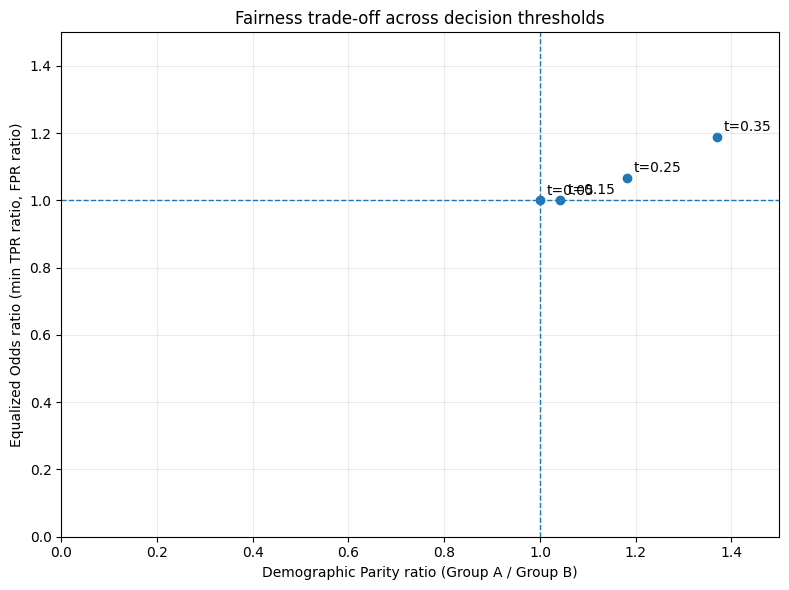

,threshold,DP_distance,EO_distance,PP_distance
0,0.05,0.0000,0.0000,0.3965
1,0.15,0.0428,0.0016,0.3413
2,0.25,0.1813,0.0675,0.2620
3,0.35,0.3694,0.1891,0.2126
4,0.45,0.7184,0.3935,0.1325
5,0.55,1.0882,0.6104,0.0770
6,0.65,1.6075,0.8286,0.0207
7,0.75,2.8228,1.8054,0.0248
8,0.85,3.4438,1.5544,0.1930
9,0.95,3.9116,NaN,0.0000


In [7]:
fair_df = X_test.copy()
fair_df["y"] = ylog_test.to_numpy()
fair_df["p"] = prob_log
# Choose two largest race groups from the test split, for test-only threshold evaluation.
race_order = fair_df["race"].value_counts()
race_groups = race_order[race_order >= 30].index[:2].tolist()
if len(race_groups) < 2:
    raise ValueError("Fewer than two race groups have 30+ test rows; cannot compute stable group ratios.")
group_a, group_b = race_groups[0], race_groups[1]
print("Group A:", group_a, "| Group B:", group_b)

def safe_ratio(a, b):
    return np.nan if (pd.isna(a) or pd.isna(b) or b == 0) else a/b

fair_rows = []
thresholds = np.round(np.arange(.05, .951, .10), 2)
for t in thresholds:
    fair_df["pred"] = (fair_df["p"] >= t).astype(int)
    rates = {}
    for g in [group_a, group_b]:
        d = fair_df[fair_df["race"] == g]
        pred, y = d["pred"].to_numpy(), d["y"].to_numpy()
        pos_rate = pred.mean() if len(d) else np.nan
        tp = ((pred==1)&(y==1)).sum(); fn=((pred==0)&(y==1)).sum()
        fp = ((pred==1)&(y==0)).sum(); tn=((pred==0)&(y==0)).sum()
        tpr = tp/(tp+fn) if (tp+fn)>0 else np.nan
        fpr = fp/(fp+tn) if (fp+tn)>0 else np.nan
        ppv = tp/(tp+fp) if (tp+fp)>0 else np.nan
        rates[g] = {"DP_rate":pos_rate,"TPR":tpr,"FPR":fpr,"PPV":ppv}
    dp = safe_ratio(rates[group_a]["DP_rate"], rates[group_b]["DP_rate"])
    tpr_ratio = safe_ratio(rates[group_a]["TPR"], rates[group_b]["TPR"])
    fpr_ratio = safe_ratio(rates[group_a]["FPR"], rates[group_b]["FPR"])
    eo = np.nan if pd.isna(tpr_ratio) or pd.isna(fpr_ratio) else min(tpr_ratio, fpr_ratio)
    pp = safe_ratio(rates[group_a]["PPV"], rates[group_b]["PPV"])
    fair_rows.append({"threshold":t,"DP_ratio":dp,"EO_ratio":eo,"PP_ratio":pp,
                      "TPR_A":rates[group_a]["TPR"],"TPR_B":rates[group_b]["TPR"],
                      "FPR_A":rates[group_a]["FPR"],"FPR_B":rates[group_b]["FPR"],
                      "PPV_A":rates[group_a]["PPV"],"PPV_B":rates[group_b]["PPV"]})
fairness = pd.DataFrame(fair_rows)
display(fairness.round(4))
plt.figure(figsize=(8,6))
plt.scatter(fairness["DP_ratio"], fairness["EO_ratio"])
for _, r in fairness.iterrows():
    if pd.notna(r["DP_ratio"]) and pd.notna(r["EO_ratio"]):
        plt.annotate(f't={r["threshold"]:.2f}', (r["DP_ratio"],r["EO_ratio"]), xytext=(5,4), textcoords="offset points")
plt.axvline(1, linestyle="--", linewidth=1)
plt.axhline(1, linestyle="--", linewidth=1)
plt.xlim(0,1.5); plt.ylim(0,1.5)
plt.xlabel("Demographic Parity ratio (Group A / Group B)")
plt.ylabel("Equalized Odds ratio (min TPR ratio, FPR ratio)")
plt.title("Fairness trade-off across decision thresholds")
plt.grid(alpha=.25)
plt.tight_layout()
plt.savefig("fairness_tradeoff.png", dpi=160)
plt.show()

# Provide best threshold candidates by absolute distance from ideal ratio 1, only as a descriptive aid.
fairness["DP_distance"] = (fairness["DP_ratio"]-1).abs()
fairness["EO_distance"] = (fairness["EO_ratio"]-1).abs()
fairness["PP_distance"] = (fairness["PP_ratio"]-1).abs()
display(fairness[["threshold","DP_distance","EO_distance","PP_distance"]].round(4))

## 8. Part 3 and Part 4 — Generate a results-grounded draft
The following cell writes a Markdown report scaffold using computed outputs. It intentionally flags areas that require your interpretation; revise in your own words, verify all statements against tables, and include the generated chart. Because results depend on the data version and execution environment, the report must be generated after running all cells.

In [8]:
def fmt(x, digits=3):
    try:
        return "NA" if pd.isna(x) else f"{float(x):.{digits}f}"
    except Exception:
        return str(x)

# Compact results summary, useful for writing evidence-based answers.
summary = {
    "seed": SEED, "filtered_rows": int(len(df)), "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)), "linear_prediction_median": lin_median,
    "mismatch_count": mismatch, "mismatch_percent": mismatch_pct,
    "linear_r2": float(linear_model.score(X_test, ylin_test)),
    "logistic_accuracy": float(accuracy_score(ylog_test, flag_log)),
    "logistic_auc": float(roc_auc_score(ylog_test, prob_log)),
    "adversarial_count": int(len(adversarial)), "adversarial_percent": 100*len(adversarial)/len(test_results),
    "race_group_A": str(group_a), "race_group_B": str(group_b),
}
with open("computed_summary.json","w") as f:
    json.dump(summary, f, indent=2)

print("COMPUTED SUMMARY")
display(pd.DataFrame([summary]).T.rename(columns={0:"value"}))
print("\nUse these actual outputs to write your final PDF. The assignment requires each Part 3 response to be around 250–300 words and the Part 4 reflection around 500 words.")

COMPUTED SUMMARY


,value
seed,72
filtered_rows,7214
train_rows,5049
test_rows,2165
linear_prediction_median,4.51545
mismatch_count,237
mismatch_percent,10.946882
linear_r2,0.447044
logistic_accuracy,0.672979
logistic_auc,0.732121



Use these actual outputs to write your final PDF. The assignment requires each Part 3 response to be around 250–300 words and the Part 4 reflection around 500 words.


## Report-writing checklist

- [ ] Preprocessing: missing values, encoding, scaling, outliers.
- [ ] Part 1: median linear prediction, 0.5 logistic threshold, model-flag confusion matrix, mismatch count and percentage.
- [ ] Part 2.1: full model and two subgroup coefficients with confidence intervals; explain reversal or meaningful difference.
- [ ] Part 2.2: before/after coefficients for at least four predictors and percentage changes.
- [ ] Part 2.3: count and percentage of high-confidence errors; compare demographic characteristics with test set; explain plausible failure mechanism.
- [ ] Part 2.4: DP/EO/PP table at all thresholds and fairness trade-off chart; quantify one trade-off.
- [ ] Part 3: answer all eight questions with actual computed values (about 250–300 words each).
- [ ] Part 4: about 500 words, explicit deployment recommendation and at least three evidence-based limitations.
- [ ] Save notebook outputs, export final report to one PDF, and provide a GitHub link to the reproducible notebook.
- [ ] Explain your choices in your own words for the oral assessment.

### Methodological cautions
1. `is_recid` means the dataset's recidivism indicator; it is not interchangeable with `two_year_recid`.
2. Group ratios are not sufficient to prove a model fair or unfair. Sample size, base rates, uncertainty, and context matter.
3. The assignment calls for policy analysis; a predictive association does not establish causation or justify deployment.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')